# Lab Assignment 1

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import AgglomerativeClustering
from sklearn.metrics import silhouette_score, davies_bouldin_score
import scipy.cluster.hierarchy as sch

In [2]:
df = pd.read_csv('CC_Customer_Dataset.csv')

In [3]:
features = [
    'Avg_Credit_Limit',
    'Total_Credit_Cards',
    'Total_visits_bank',
    'Total_visits_online',
    'Total_calls_made'
]
X = df[features]

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

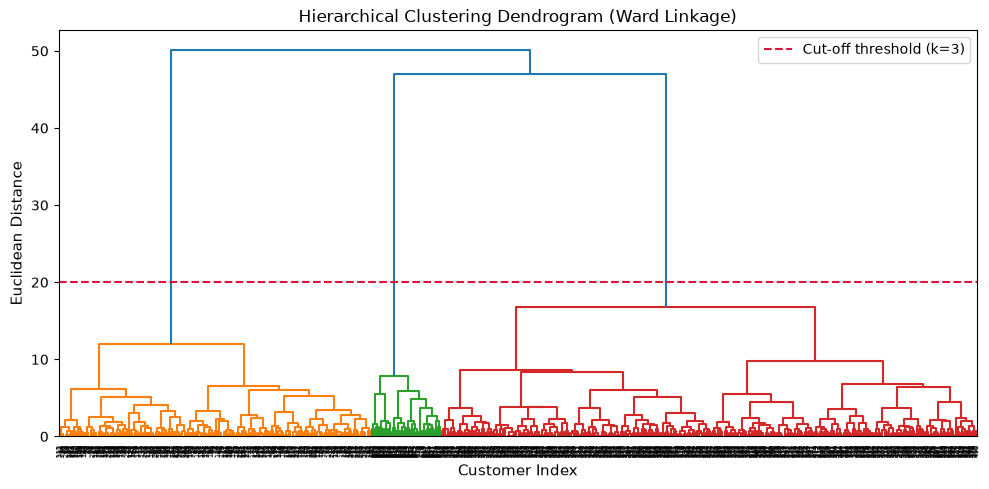

In [8]:
plt.figure(figsize=(10, 5))
dendrogram = sch.dendrogram(sch.linkage(X_scaled, method='ward'))
plt.title('Hierarchical Clustering Dendrogram (Ward Linkage)', fontsize=12)
plt.xlabel('Customer Index', fontsize=11)
plt.ylabel('Euclidean Distance', fontsize=11)
plt.axhline(y=20, color='crimson', linestyle='--', label='Cut-off threshold (k=3)')
plt.legend()
plt.tight_layout()
plt.show()

In [9]:
agg = AgglomerativeClustering(n_clusters=3, linkage='ward')
df['Cluster'] = agg.fit_predict(X_scaled)

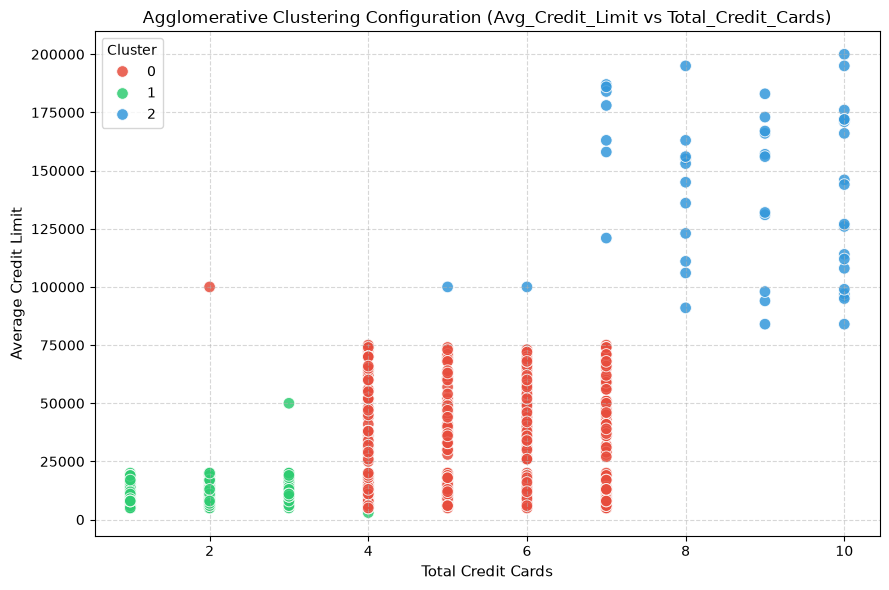

In [10]:
plt.figure(figsize=(9, 6))
palette = ['#e74c3c', '#2ecc71', '#3498db']
sns.scatterplot(
    data=df,
    x='Total_Credit_Cards',
    y='Avg_Credit_Limit',
    hue='Cluster',
    palette=palette,
    s=70,
    alpha=0.85
)
plt.title('Agglomerative Clustering Configuration (Avg_Credit_Limit vs Total_Credit_Cards)', fontsize=12)
plt.xlabel('Total Credit Cards', fontsize=11)
plt.ylabel('Average Credit Limit', fontsize=11)
plt.legend(title='Cluster', loc='upper left')
plt.grid(True, linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

In [11]:
sil = silhouette_score(X_scaled, df['Cluster'])
dbi = davies_bouldin_score(X_scaled, df['Cluster'])

print(f"Silhouette Score: {sil:.4f}")
print(f"Davies-Bouldin Index (DBI): {dbi:.4f}")

Silhouette Score: 0.5148
Davies-Bouldin Index (DBI): 0.6810
